# Libraries

In [1]:
%matplotlib inline

In [2]:
from perceval.components.unitary_components import PS, BS
from perceval.rendering.circuit import DisplayConfig, SymbSkin
import numpy as np
from pathlib import Path
import perceval as pcvl
from perceval import BasicState
import os
import glob
import time
from datetime import datetime
from tqdm import tqdm

import itertools as it
from scipy.optimize import minimize

import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

from tqdm.auto import tqdm

from scipy.optimize import minimize, OptimizeResult
from scipy.optimize import dual_annealing
from uncertainties import unumpy
import ipywidgets as widgets
from IPython.display import display, clear_output
from uncertainties import ufloat

# Circuit Design

In [3]:
# m = 12

# circuit = pcvl.components.GenericInterferometer(m,
#                                 fun_gen = lambda idx: (pcvl.Circuit(2, name='mzi')
#                                                        .add(0, PS(pcvl.P(f"phi_{idx}"))))
#                                                        .add(0, BS())
#                                                        .add(0, PS(pcvl.P(f"theta_{idx}")))
#                                                        .add(0, BS()),
#                                                 shape= pcvl.InterferometerShape.RECTANGLE)
# symbolic_skin = SymbSkin(compact_display=True)
# pcvl.pdisplay(circuit, skin=symbolic_skin)

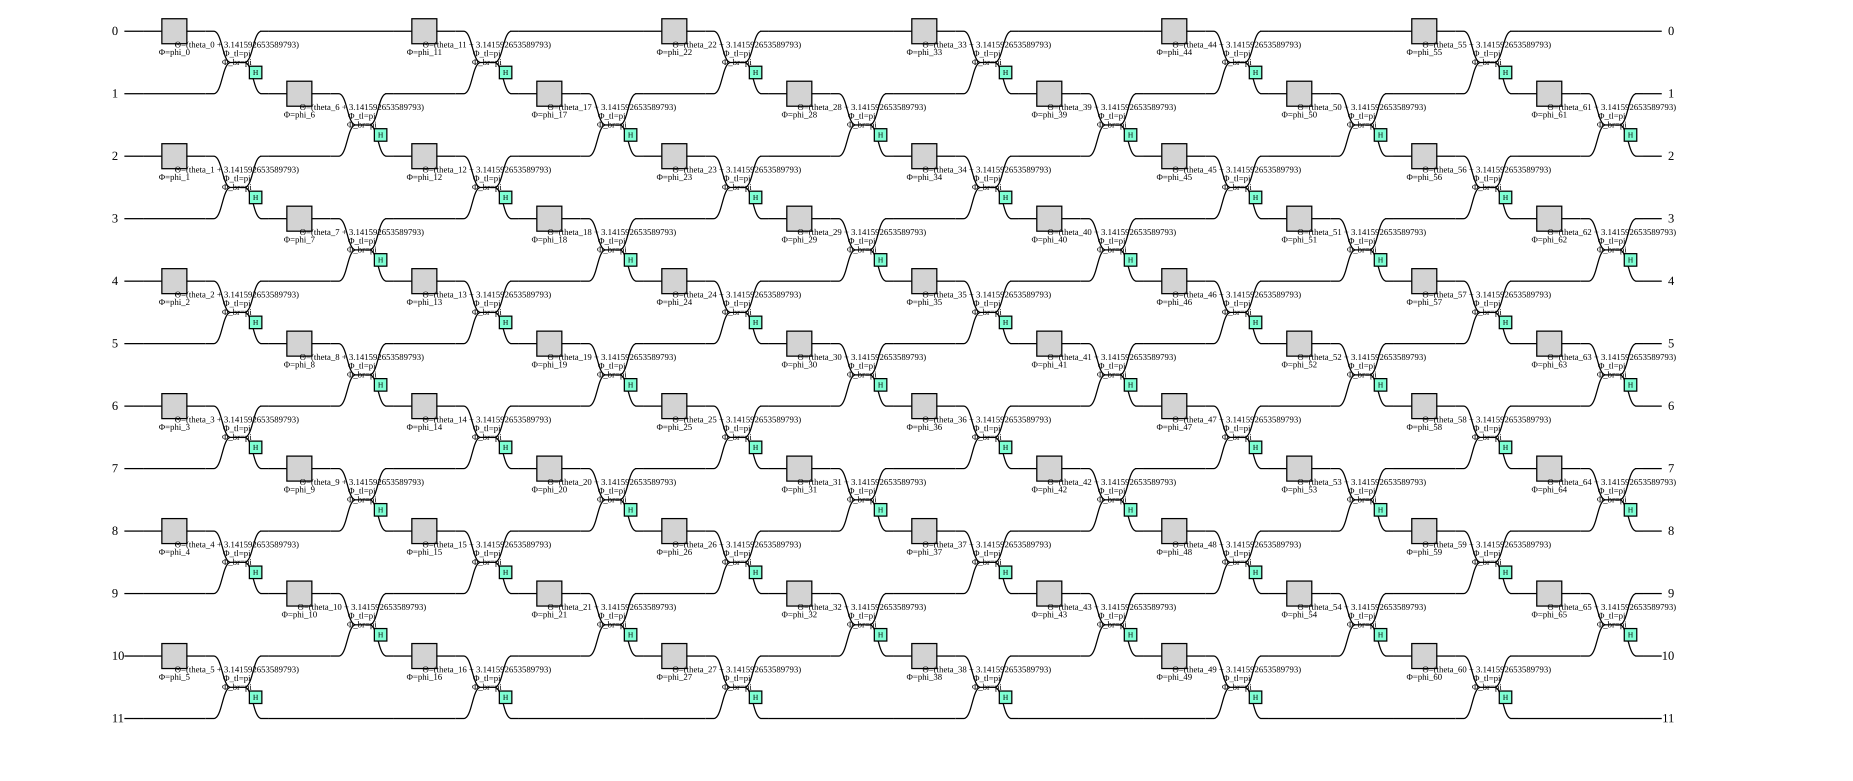

In [4]:
m = 12

circuit = pcvl.components.GenericInterferometer(m,
                                fun_gen = lambda idx: (pcvl.Circuit(2, name='mzi')
                                                       .add(0, PS(pcvl.P(f"phi_{idx}"))))
                                                       .add(0, BS.H(theta=pcvl.P(f"theta_{idx}") + np.pi, phi_tl = np.pi, phi_br = np.pi)),
                                                shape= pcvl.InterferometerShape.RECTANGLE)
symbolic_skin = SymbSkin(compact_display=True)
pcvl.pdisplay(circuit, skin=symbolic_skin)

# Parameters, Input and Output States

In [5]:
parameters = circuit.get_parameters()
par_e = parameters[::2]
par_i = parameters[1::2]

In [6]:
out_states = [[1,0,1,0],[1,0,0,1],[0,1,1,0],[0,1,0,1]]
out_states = [[0,0]+j+[0]*6 for j in out_states]
out_states = [pcvl.BasicState(i) for i in out_states]
out_states

[|0,0,1,0,1,0,0,0,0,0,0,0>,
 |0,0,1,0,0,1,0,0,0,0,0,0>,
 |0,0,0,1,1,0,0,0,0,0,0,0>,
 |0,0,0,1,0,1,0,0,0,0,0,0>]

In [7]:
V = 0.9

x = np.arccos(2*V-1)
v1 = BasicState("|{0}>")
v2 = pcvl.StateVector("|{1}>")
phase = complex(np.exp(1j*x))
in_state = BasicState("|0,0>")*(v1+v2)*BasicState("|0>")*(v1+phase*v2)*BasicState("|0,0,0,0,0,0,0>")
in_state

(0.4+0.3I)*|0,0,{1},0,{1},0,0,0,0,0,0,0>+0.5*|0,0,{0},0,{0},0,0,0,0,0,0,0>+0.5*|0,0,{1},0,{0},0,0,0,0,0,0,0>+(0.4+0.3I)*|0,0,{0},0,{1},0,0,0,0,0,0,0>

# Simulation Functions



## Circuit Simulation

In [8]:
processor = pcvl.Processor("Naive")

In [9]:
calls = 0

def circ_sim(f_i, f_e, n_shots=1e9):
    global calls
    calls += 1

    for i,p in enumerate(par_e):
        p.set_value(f_e[i])

    for j,q in enumerate(par_i):
        q.set_value(f_i[j])

    processor.set_circuit(circuit)
    simulator = pcvl.SimulatorFactory().build(processor)

    P_I = [] 

    for s in out_states:
        p_I = simulator.probability(in_state,s)
        P_I.append(p_I)

    PP = np.array(P_I)
    CC = np.random.poisson(PP*n_shots)

    return CC

def circ_sim_prob(f_i, f_e, n_shots=1e9):
    global calls
    calls += 1

    for i,p in enumerate(par_e):
        p.set_value(f_e[i])

    for j,q in enumerate(par_i):
        q.set_value(f_i[j])

    processor.set_circuit(circuit)
    simulator = pcvl.SimulatorFactory().build(processor)

    P_I = [] 

    for s in out_states:
        p_I = simulator.probability(in_state,s)
        P_I.append(p_I)

    PP = np.array(P_I)

    return PP

'10parameters' scheme

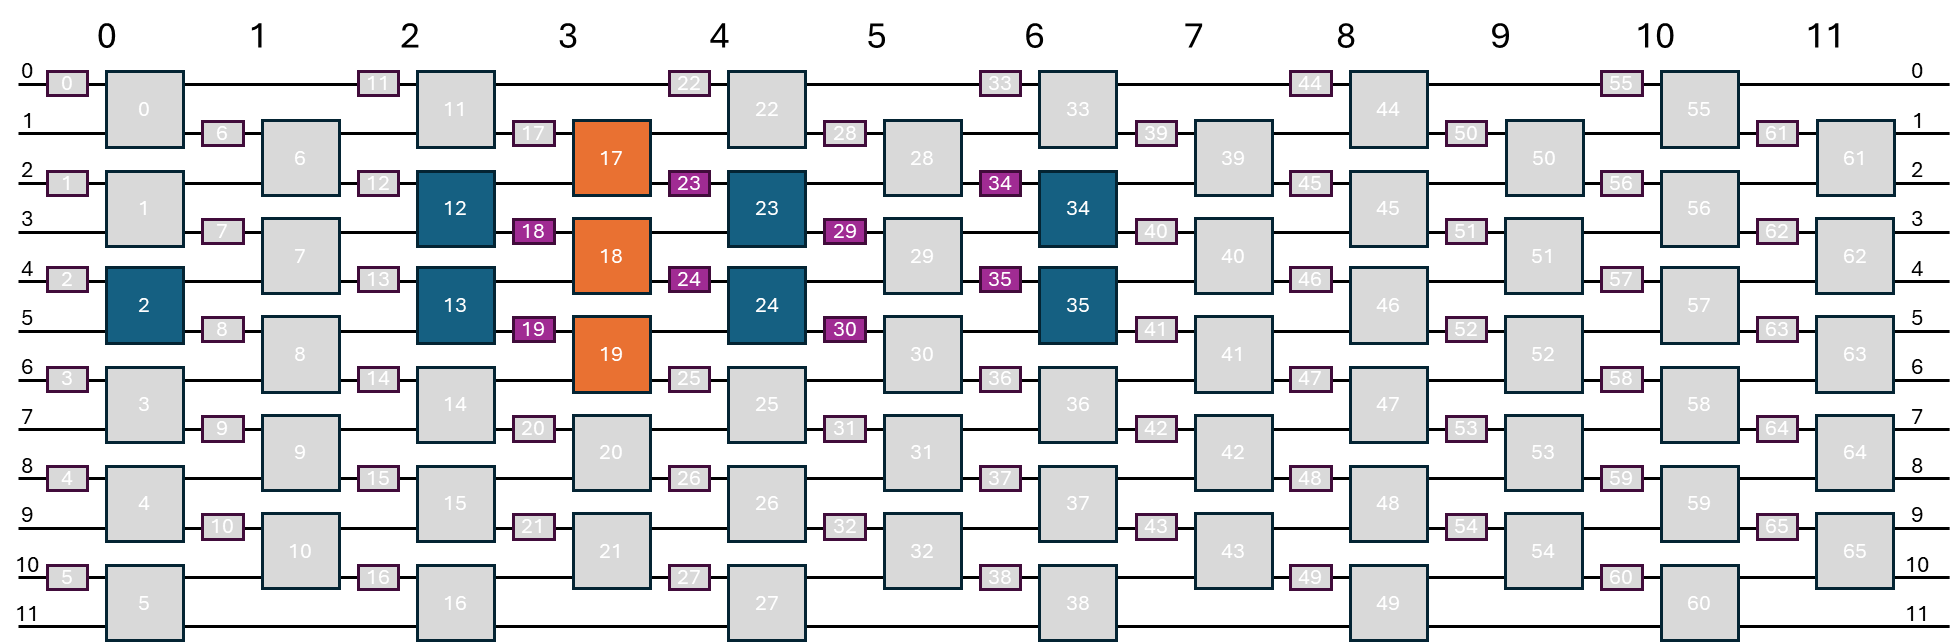

'qlass' scheme

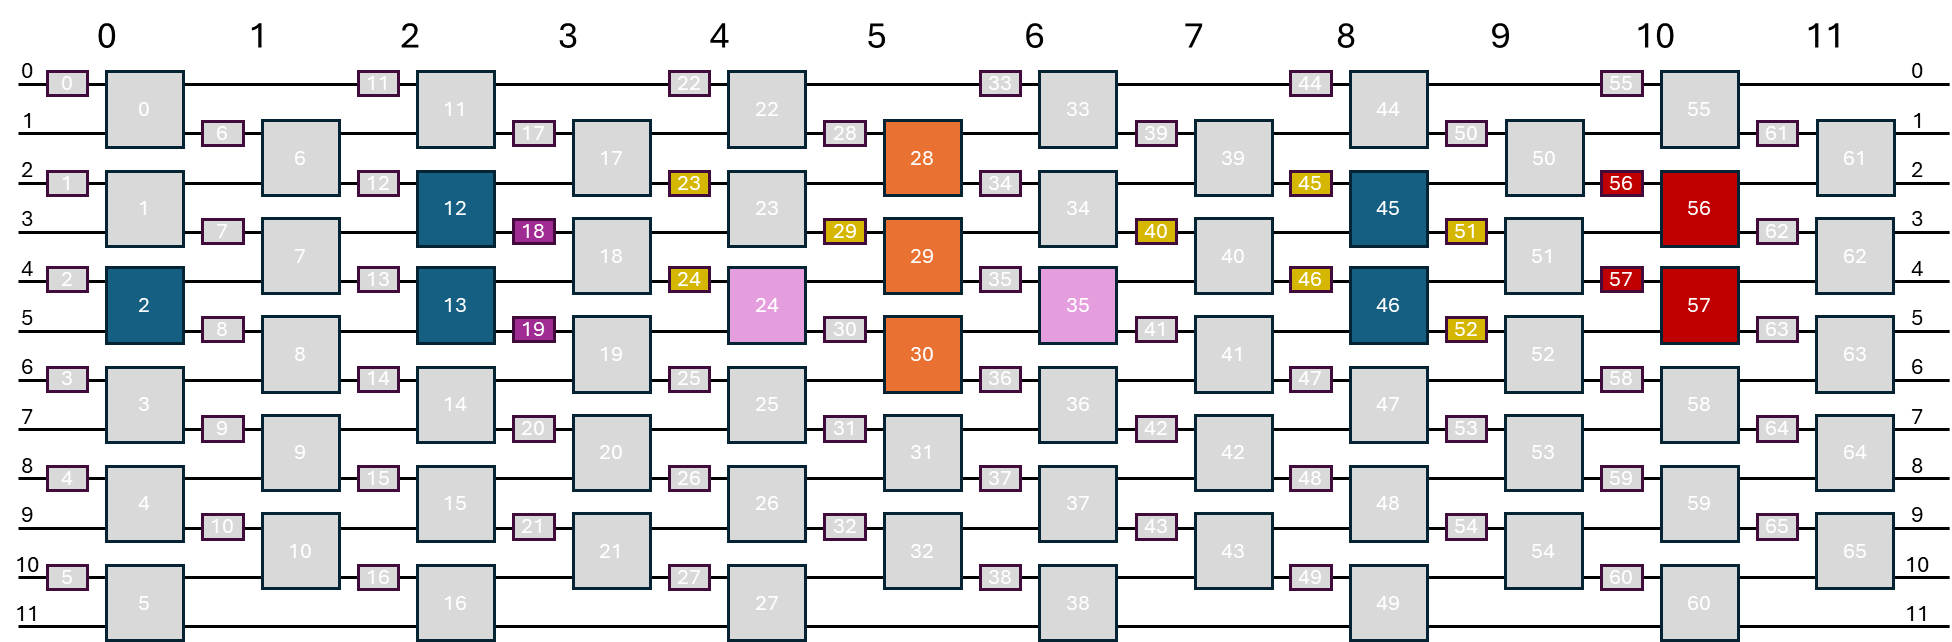

## Measurement function

In [10]:
# def P_calc(x, measurement_group, inv = False, scheme='qlass'):
#     if scheme == '10parameters':
#         theta_par = [12,13,23,24]
#         phi_par = [18,19,23,24,29,30]
#         theta_cnot = [17,18,19]
#         theta_meas = [34,35]
#         phi_meas = [34,35]
#         inv_c = 2
        
#         # chip initialization
#         theta = np.full(66,np.pi)
#         phi = np.zeros(66)
        
#         # set internal and external phases
#         theta[theta_cnot] = [-np.arccos(1/3),-np.arccos(1/3),np.arccos(1/3)]
#         theta[theta_par] = x[:len(theta_par)]
#         phi[phi_par] = x[len(theta_par):]

#     if scheme == 'qlass':
#         theta_par = [12,13,45,46]
#         theta_cnot_ext = [24,35]
#         theta_cnot = [28,29,30]
#         theta_meas = [56,57]
#         phi_meas = [56,57]
#         offset_phases = [23,24,29,40,45,46,51,52]
#         inv_c = 2        
#         adjust_Ry = [23,24,51,52]
        
#         # chip initialization
#         theta = np.full(66,np.pi)
#         phi = np.zeros(66)
        
#         # set internal and external phases
#         theta[theta_cnot] = [-np.arccos(1/3),-np.arccos(1/3),np.arccos(1/3)]
#         theta[theta_cnot_ext] = [np.pi/2]*2
#         # thetas_from_R = 2*np.arcsin(x)
#         theta[theta_par] = x #+ np.pi
#         phi[offset_phases] = np.pi
#         # phi[adjust_Ry] = np.pi
    
#     if inv:
#         theta[inv_c] = 0

#     meas_circ = {'I': {'phi': [0], 'theta': [np.pi]},
#                  'X': {'phi': [0], 'theta': [np.pi/2]},
#                  'Y': {'phi': [np.pi/2], 'theta': [np.pi/2]},
#                  'Z': {'phi': [0], 'theta': [np.pi]}}

#     results = {}
#     for op in measurement_group:
#         theta[theta_meas] = meas_circ[op[0]]['theta'] + meas_circ[op[1]]['theta']
#         phi[phi_meas] = meas_circ[op[0]]['phi'] + meas_circ[op[1]]['phi']
#         results[op] = circ_sim(theta, phi)
#     return results

# def Prob_calc(x, measurement_group, inv = False, scheme='qlass'):
#     if scheme == '10parameters':
#         theta_par = [12,13,23,24]
#         phi_par = [18,19,23,24,29,30]
#         theta_cnot = [17,18,19]
#         theta_meas = [34,35]
#         phi_meas = [34,35]
#         inv_c = 2
        
#         # chip initialization
#         theta = np.full(66,np.pi)
#         phi = np.zeros(66)
        
#         # set internal and external phases
#         theta[theta_cnot] = [np.arccos(1/3)]*3
#         theta[theta_par] = x[:len(theta_par)]
#         phi[phi_par] = x[len(theta_par):]

#     if scheme == 'qlass':
#         theta_par = [12,13,45,46]
#         theta_cnot_ext = [24,35]
#         theta_cnot = [28,29,30]
#         theta_meas = [56,57]
#         phi_meas = [56,57]
#         offset_phases = [23,24,29,40,45,46,51,52]
#         inv_c = 2        

#         # chip initialization
#         theta = np.full(66,np.pi)
#         phi = np.zeros(66)
        
#         # set internal and external phases
#         theta[theta_cnot] = [-np.arccos(1/3),-np.arccos(1/3),np.arccos(1/3)]
#         theta[theta_cnot_ext] = [np.pi/2]*2
#         # thetas_from_R = 2*np.arcsin(x)
#         theta[theta_par] = x
#         phi[offset_phases] = np.pi
    
#     if inv:
#         theta[inv_c] = 0

#     meas_circ = {'I': {'phi': [0], 'theta': [np.pi]},
#                  'X': {'phi': [0], 'theta': [np.pi/2]},
#                  'Y': {'phi': [np.pi/2], 'theta': [np.pi/2]},
#                  'Z': {'phi': [0], 'theta': [np.pi]}}

#     results = {}
#     for op in measurement_group:
#         theta[theta_meas] = meas_circ[op[0]]['theta'] + meas_circ[op[1]]['theta']
#         phi[phi_meas] = meas_circ[op[0]]['phi'] + meas_circ[op[1]]['phi']
#         results[op] = circ_sim_prob(theta, phi)
#     return results

In [11]:
def prepare_qubit(theta, phi, state, bs, ps):
    theta[bs] = 2*np.arcsin(np.abs(state[0]))
    phi[ps] = np.angle(state[1]) - np.angle(state[0])
    # print(f'prepared {state} as ')
    # print(theta[bs], phi[ps])
    return theta, phi
        
def P_calc(x, measurement_group, input_states, scheme='qlass'):
    if scheme == '10parameters':
        theta_par = [12,13,23,24]
        phi_par = [18,19,23,24,29,30]
        theta_cnot = [17,18,19]
        theta_meas = [34,35]
        phi_meas = [34,35]
        state0_bs = 1
        state0_ps = 7
        state1_bs = 2
        state1_ps = 8

        
        # chip initialization
        theta = np.full(66,np.pi)
        phi = np.zeros(66)

        # prepare ansatz
        prepare_qubit(theta, phi, input_states[0], state0_bs, state0_ps)
        prepare_qubit(theta, phi, input_states[1], state1_bs, state1_ps)
        
        # set internal and external phases
        theta[theta_cnot] = [-np.arccos(1/3),-np.arccos(1/3),np.arccos(1/3)]
        theta[theta_par] = x[:len(theta_par)]
        phi[phi_par] = x[len(theta_par):]

    if scheme == 'qlass':
        theta_par = [12,13,45,46]
        theta_cnot_ext = [24,35]
        theta_cnot = [28,29,30]
        theta_meas = [56,57]
        phi_meas = [56,57]
        offset_phases = [12,13,23,24,29,40,45,46,51,52]

        # [for expectation values with no rotations, in debugging]
        # offset_phases = [12,13,18,19,23,24,29,40,45,46]
        
        adjust_Ry = [23,24,51,52]
        state0_bs = 1
        state0_ps = 7
        state1_bs = 2
        state1_ps = 8
        
        # chip initialization
        theta = np.full(66,np.pi)
        phi = np.zeros(66)

        # prepare ansatz
        prepare_qubit(theta, phi, input_states[0], state0_bs, state0_ps)
        prepare_qubit(theta, phi, input_states[1], state1_bs, state1_ps)
        
        # set internal and external phases
        theta[theta_cnot] = [-np.arccos(1/3),-np.arccos(1/3),np.arccos(1/3)]
        theta[theta_cnot_ext] = [np.pi/2]*2
        # thetas_from_R = 2*np.arcsin(x)
        theta[theta_par] = x #+ np.pi
        phi[offset_phases] = np.pi
        # phi[adjust_Ry] = np.pi

    meas_circ = {'I': {'phi': [0], 'theta': [np.pi]},
                 'X': {'phi': [0], 'theta': [np.pi/2]},
                 'Y': {'phi': [np.pi/2], 'theta': [np.pi/2]},
                 'Z': {'phi': [0], 'theta': [np.pi]}}

    results = {}
    for op in measurement_group:
        theta[theta_meas] = meas_circ[op[0]]['theta'] + meas_circ[op[1]]['theta']
        phi[phi_meas] = meas_circ[op[0]]['phi'] + meas_circ[op[1]]['phi']
        results[op] = circ_sim(theta, phi)
    return results

## Hamiltonian and gradient computation

In [12]:
def expected_value(cc, A, B, eig, tot=None):
    signs = np.kron(eig[A], eig[B])
    if tot == None:
        tot = cc.sum()
    if tot == 0:
        return 0
    return (signs * cc).sum() / tot

def S1(x, H_terms, measurement_groups, inv = False, Error = False, scheme = 'qlass'):

    n = len(x)

    results = P_calc(x, measurement_groups, inv, scheme = scheme)
    if Error:
        results = {k: unumpy.uarray(v, np.sqrt(v + 1)) for k, v in results.items()}
        
    # Hamiltonian computation

    eig = {'I': np.array([1,  1]),
           'X': np.array([1, -1]),
           'Y': np.array([1, -1]),
           'Z': np.array([1, -1])}
    
    pauli_groupings = {'II': 'II', 'IX': 'XX', 'IY': 'YY', 'IZ': 'ZZ',
                       'XI': 'XX', 'XX': 'XX', 'XY': 'XY', 'XZ': 'XZ',
                       'YI': 'YY', 'YX': 'YX', 'YY': 'YY', 'YZ': 'YZ',
                       'ZI': 'ZZ', 'ZX': 'ZX', 'ZY': 'ZY', 'ZZ': 'ZZ'}
     
    exp_values = ({op: expected_value(results[pauli_groupings[op]],op[0],op[1],eig) for op in H_terms if op != 'II'})
    exp_values['II'] = 1

    coeffs = np.array(list(H_terms.values()))
    expval  = np.array([exp_values[op] for op in H_terms])
    H = coeffs @ expval

    # gradient computation
    if not Error:
        grad_H = []
        for i in range(n):
            x_s = np.copy(x)
            x_s[i] += np.pi/2
            res1 = P_calc(x_s, measurement_groups, inv, scheme = scheme)
            
            x_s = np.copy(x)
            x_s[i] -= np.pi/2
            res2 = P_calc(x_s, measurement_groups, inv, scheme = scheme)

            dres = {op: (res1[op] - res2[op])/2 for op in measurement_groups}
            dres['II'] = np.array([0])
            
            dexp_values = ({op: expected_value(dres[pauli_groupings[op]],op[0],op[1],eig, tot=results[pauli_groupings[op]].sum()) - exp_values[op] * dres[pauli_groupings[op]].sum() / results[pauli_groupings[op]].sum() for op in H_terms if op != 'II'})
            dexp_values['II'] = 0
            dexpval = np.array([dexp_values[op] for op in H_terms])
            dH = coeffs @ dexpval
            grad_H.append(dH)
            
        return H, np.array(grad_H)
    else:
        return H.nominal_value, H.std_dev

def S(x, H_terms, measurement_groups, weights, scheme):
    H1, Grad1 = S1(x, H_terms, measurement_groups, inv=False, Error=False, scheme = scheme)
    H2, Grad2 = S1(x, H_terms, measurement_groups, inv=True, Error=False, scheme = scheme)
    return weights[0]*H1 + weights[1]*H2, weights[0]*Grad1 + weights[1]*Grad2

In [13]:
def expected_value(cc, A, B, eig, tot=None):
    signs = np.kron(eig[A], eig[B])
    if tot == None:
        tot = cc.sum()
    # if tot == 0:
    #     return 0
    return (signs * cc).sum() / tot

eig = {'I': np.array([1,  1]),
           'X': np.array([1, -1]),
           'Y': np.array([1, -1]),
           'Z': np.array([1, -1])}
    
pauli_groupings = {'II': 'ZZ', 'IX': 'XX', 'IY': 'YY', 'IZ': 'ZZ',
                   'XI': 'XX', 'XX': 'XX', 'XY': 'XY', 'XZ': 'XZ',
                   'YI': 'YY', 'YX': 'YX', 'YY': 'YY', 'YZ': 'YZ',
                   'ZI': 'ZZ', 'ZX': 'ZX', 'ZY': 'ZY', 'ZZ': 'ZZ'}

# pauli_groupings = {'II': 'II', 'IX': 'IX', 'IY': 'IY', 'IZ': 'IZ',
#                      'XI': 'XI', 'XX': 'XX', 'XY': 'XY', 'XZ': 'XZ',
#                      'YI': 'YI', 'YX': 'YX', 'YY': 'YY', 'YZ': 'YZ',
#                      'ZI': 'ZI', 'ZX': 'ZX', 'ZY': 'ZY', 'ZZ': 'ZZ'}

def S1_energy(x, H_terms, measurement_groups, input_states, Error = False, scheme = 'qlass'):
    
    n = len(x)

    results = P_calc(x, measurement_groups, input_states, scheme = scheme)
    
    if Error:
        results = {k: unumpy.uarray(v, np.sqrt(v + 1)) for k, v in results.items()}
        
    # Hamiltonian computation

    exp_values = ({op: expected_value(results[pauli_groupings[op]],op[0],op[1],eig) for op in H_terms})# if op != 'II'})
    # if Error:
    #     exp_values['II'] = ufloat(1,0)
    # else:
    #     exp_values['II'] = 1
    coeffs = np.array(list(H_terms.values()))
    expval  = np.array([exp_values[op] for op in H_terms])
    H = coeffs @ expval
    if not Error:
        return H
    else:
        return H.nominal_value, H.std_dev

def S_energy(x, H_terms, measurement_groups, input_states, weights, scheme = 'qlass'):
    H1 = S1_energy(x, H_terms, measurement_groups, input_states[0], Error=False, scheme = scheme)
    H2 = S1_energy(x, H_terms, measurement_groups, input_states[1], Error=False, scheme = scheme)
    return weights[0]*H1 + weights[1]*H2

In [14]:
sigma = {'I': np.array([[1,0],[0,1]], dtype=complex),
         'X': np.array([[0,1],[1,0]], dtype=complex),
         'Y': np.array([[0,-1j],[1j,0]], dtype=complex),
         'Z': np.array([[1,0],[0,-1]], dtype=complex)}

def hamiltonian_matrix(H_terms, dim=4):
    
    H = np.zeros((dim,dim), dtype=complex)
    for pauliop, coeff in H_terms.items():
        O = np.kron(sigma[pauliop[0]],sigma[pauliop[1]])
        H += coeff * O
    eigenvalues = np.sort(np.linalg.eigvals(H)).real
    return H, eigenvalues

In [15]:
def ground_state(x, H_terms, measurement_groups, input_states, scheme = 'qlass'):
    H1 = S1_energy(x, H_terms, measurement_groups, input_states, Error=False, scheme = scheme)
    # H2 = S1_energy(x, H_terms, measurement_groups, inv=True, Error=False, scheme = scheme)
    return H1

def excited_state(x, H_terms, measurement_groups, input_states, scheme = 'qlass'):
    # H1 = S1_energy(x, H_terms, measurement_groups, input_states, Error=False, scheme = scheme)
    H2 = S1_energy(x, H_terms, measurement_groups, input_states, Error=False, scheme = scheme)
    return H2

## Quantum State Tomography

In [26]:
complete_meas = ['II', 'XX', 'YY', 'ZZ', 'YX', 'ZX', 'XY', 'ZY', 'XZ', 'YZ']
pauli_groupings = {'II': 'ZZ', 'IX': 'XX', 'IY': 'YY', 'IZ': 'ZZ',
                   'XI': 'XX', 'XX': 'XX', 'XY': 'XY', 'XZ': 'XZ',
                   'YI': 'YY', 'YX': 'YX', 'YY': 'YY', 'YZ': 'YZ',
                   'ZI': 'ZZ', 'ZX': 'ZX', 'ZY': 'ZY', 'ZZ': 'ZZ'}
eig = {'I': np.array([1,  1]),
       'X': np.array([1, -1]),
       'Y': np.array([1, -1]),
       'Z': np.array([1, -1])}
pauli = {'I': np.array([[1,0],[0,1]], dtype=complex),
         'X': np.array([[0,1],[1,0]], dtype=complex),
         'Y': np.array([[0,-1j],[1j,0]], dtype=complex),
         'Z': np.array([[1,0],[0,-1]], dtype=complex)}

def qst(x, input_states, phi_meas = [56,57], theta_meas = [56,57], Error=True, scheme = 'qlass'):
    n = len(input_states)
    rhos = np.zeros((2,4,4), dtype=complex)

    for i in range(n):
        results = P_calc(x, complete_meas, input_states[i], scheme = scheme)
        if Error:
            results = {k: unumpy.uarray(v, np.sqrt(v + 1)) for k, v in results.items()}
            
        ev = {}
        for op in pauli_groupings:
            ev[op] = expected_value(results[pauli_groupings[op]], op[0], op[1], eig)
        
        for op in ev:
            rhos[i] += ev[op] * np.kron(pauli[op[0]], pauli[op[1]])
        rhos[i] = rhos[i]/4
        
    return rhos

# Simulation

In [17]:
N = 1
SCHEME = 'qlass'

if SCHEME == '10parameters':
    N_par = 10
if SCHEME == 'qlass':
    N_par = 4

# fix the inital conditions to compare different simulations
r0 = [np.random.uniform(0,2*np.pi,N_par) for _ in range(N)]
# r0 = [np.random.rand(N_par)+np.pi for _ in range(N)]
# r0 = [0,0,0,0]

In [18]:
# Iteration 1
shots = 1e9
n_qubits = 2
n_occ = 2 # number of occupied states
# params = np.random.rand(4)
dim = 2 ** n_qubits
input_states = [[[1,0],[1,0]],
                [[1,0],[0,1]]]

H_1 = {'II': -0.44216633, 'IX':-0.2458943, 'IZ':-0.36997974, 'XI':-0.07340748, 'XX':0.00097788, 'XZ':-1*0.07417185, 'YY': 0.03523796, 'ZI':-0.44476681, 'ZX':-0.04444575, 'ZZ':-0.41780773}
# H_1 = {'II': -0.44216633, 'XI':-0.07340748, 'ZI':-0.44476681} # this works
# H_1 = {'IZ':1.0}
measurement_groups = ['ZZ', 'XX', 'XZ', 'ZX', 'YY']
# measurement_groups = ['II', 'XX', 'YY', 'ZZ', 'YX', 'ZX', 'XY', 'ZY', 'XZ', 'YZ'] # COMPLETE GROUP

weights = [0.5,0.5]

In [19]:
H1, energies = hamiltonian_matrix(H_1, dim)
print(f'E_0 = {energies[0]}')
print(f'E_1 = {energies[1]}')
print(f'trace={energies[0] + energies[1]}')
print(f'cost={weights[0]*energies[0] + weights[1]*energies[1]}')

E_0 = -1.7387738340131964
E_1 = -0.2079616032934246
trace=-1.946735437306621
cost=-0.9733677186533105


In [20]:
log_output = widgets.Output()
display(log_output)

Output()

In [21]:
plot_output = widgets.Output()
display(plot_output)

Output()

In [22]:
os.makedirs('Simulations/DFT', exist_ok=True)


def callback(x, H_terms, measurement_groups, input_states, weights, E0_true = -1.72864826, E1_true = -0.2473062):
    global E
    v1,e1 = S1_energy(x, H_terms, measurement_groups, input_states[0], Error = True, scheme = SCHEME)
    v2,e2 = S1_energy(x, H_terms, measurement_groups, input_states[1], Error = True, scheme = SCHEME)
    
    cost.append(weights[0]*v1 + weights[1]*v2)
    E1.append(v1)
    E2.append(v2)

    cost_e.append(weights[0]*e1 + weights[1]*e2)
    E1_e.append(e1)
    E2_e.append(e2)

    trace.append(v1+v2)
    trace_e.append(e1+e2)
    
    trace_true = E0_true + E1_true
    cost_true = weights[0]*E0_true + weights[1]*E1_true
    
    xs = np.arange(len(cost))
    with plot_output:
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.set_xlabel("Step")
        ax.set_ylabel("E (Hartree)")
        ax.axhline(y=trace_true, color='green', linewidth=1, label='trace')
        ax.axhline(y=cost_true, color='blue', linewidth=1, label='cost')
        ax.axhline(y=E0_true, color='orange', linewidth=1, label='E_0')
        ax.axhline(y=E1_true, color='purple', linewidth=1, label='E_1')
        
        ax.errorbar(xs, E1, E1_e, fmt='.', color='orange', capsize=3)
        ax.plot(xs, E1, 'o-', color='orange', linewidth=1)
        
        ax.errorbar(xs, E2, E2_e, fmt='.', color='purple', capsize=3)
        ax.plot(xs, E2, 'o-', color='purple', linewidth=1)
        
        ax.errorbar(xs, trace, trace_e, fmt='g.', capsize=3)
        ax.plot(xs, trace, 'go-', linewidth=1)
        
        ax.errorbar(xs, cost, cost_e, fmt='g.', capsize=3)
        ax.plot(xs, cost, 'o-', color='blue', linewidth=1)
        
        ax.set_title(f"Run {k}  |  step {len(cost)-1}  | Calls {calls} | ΔE={cost[-1]-E0_true:+.5f}")
        ax.legend()
        plt.tight_layout()
        plt.show()
        plt.close(fig)

for k in tqdm(range(N)):
    calls = 0
    cost = []
    E1 = []
    E2 = []
    cost_e = []
    E1_e = []
    E2_e = []
    trace = []
    trace_e = []
    
    # res = minimize(S, x0 = r0[k], args = (H_1, measurement_groups, input_states, weights, SCHEME), method = 'BFGS', jac = True, callback = lambda x: callback(x, H_1, measurement_groups, input_states, weights, energies[0], energies[1]))
    res = minimize(S_energy, x0 = r0[k], args = (H_1, measurement_groups, input_states, weights, SCHEME), method = 'COBYLA', callback = lambda x: callback(x, H_1, measurement_groups, input_states, weights, energies[0], energies[1]))
    # res = minimize(ground_state, x0 = r0[k], args = (H_1, measurement_groups, input_states, SCHEME), method = 'COBYLA', callback = lambda x: callback(x, H_1, measurement_groups, input_states, weights, energies[0], energies[1]))
    # res = minimize(excited_state, x0 = r0[k], args = (H_1, measurement_groups, input_states, SCHEME), method = 'COBYLA', callback = lambda x: callback(x, H_1, measurement_groups, input_states, weights, energies[0], energies[1]))
    optimized_parameters = res.x
    with log_output:
        print(f'Total calls: {calls}')
    # np.savez(f'Simulations/DFT/DFT_run_{k:03d}', calls = calls, E = E, E1 = E1, E2 = E2, E_e = E_e, E1_e = E1_e, E2_e = E2_e) 

  0%|          | 0/1 [00:00<?, ?it/s]

## Final state tomography

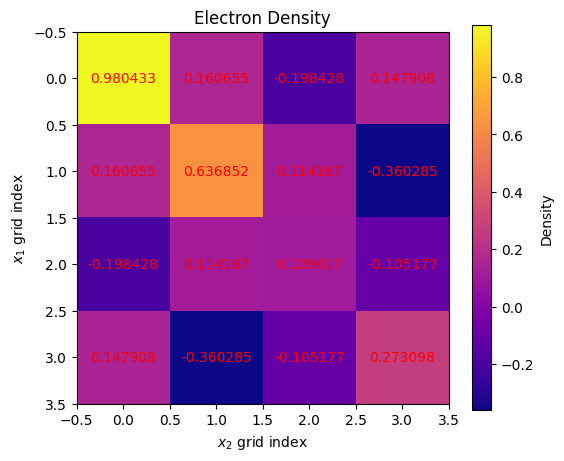

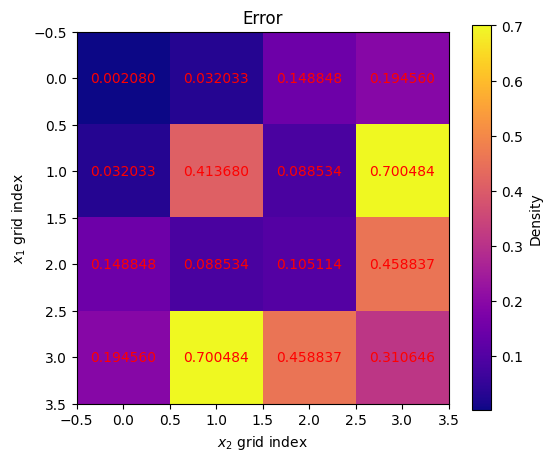

In [32]:
rho = qst(x, input_states, Error=False, scheme = 'qlass')
density = rho[0]+rho[1]

def plot_density(density, title="Electron Density"):
    plt.figure(figsize=(6,5))
    plt.imshow(density, cmap="plasma")
    for i in range(density.shape[0]):
        for j in range(density.shape[1]):
            plt.text(j, i, f"{density[i, j]:.6f}", ha='center', va='center', color='red')
    plt.colorbar(label="Density")
    plt.title(title)
    plt.xlabel(r"$x_2$ grid index")
    plt.ylabel(r"$x_1$ grid index")
    plt.show()

plot_density(density.real)

D_1 = np.array([[ 0.97835306,  0.12862265, -0.04958019, -0.04665151],
 [ 0.12862265,  0.22317224,  0.20270098,  0.34019835],
 [-0.04958019,  0.20270098,  0.21473099,  0.35366045],
 [-0.04665151,  0.34019835,  0.35366045,  0.58374371]]) # from statevector simulation

error_D1 = np.abs(D_1 - density.real)
plot_density(error_D1, "Error")

# Measurement analysis

In [29]:
data = np.load(f'../measurements/2026-05-19/DFT_run_000.npz')
E1_exp = np.array(data['E1'])
E2_exp = np.array(data['E2'])
cost_exp = np.array(data['cost'])
calls_exp = data['calls']

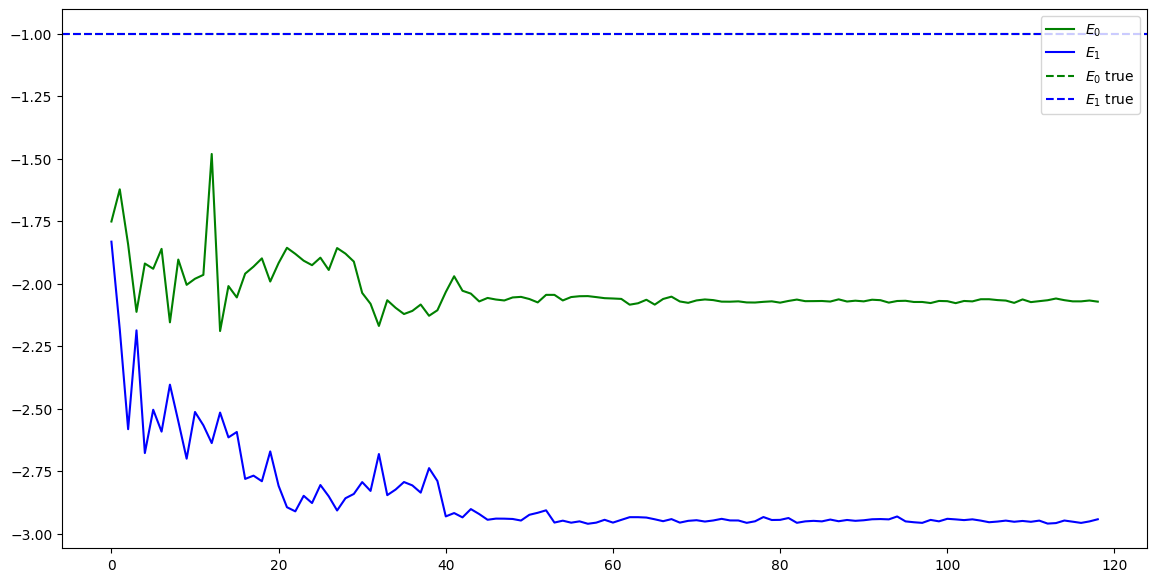

In [30]:
fig, ax = plt.subplots(figsize=(14,7))

ax.plot(range(len(E1_exp)), E1_exp, color='green', label=f'$E_0$')
ax.plot(range(len(E2_exp)), E2_exp, color='blue', label=f'$E_1$')
ax.axhline(energies[0], ls='--', color='green', label=f'$E_0$ true')
ax.axhline(energies[1], ls='--', color='blue', label=f'$E_1$ true')

ax.legend()
plt.show()

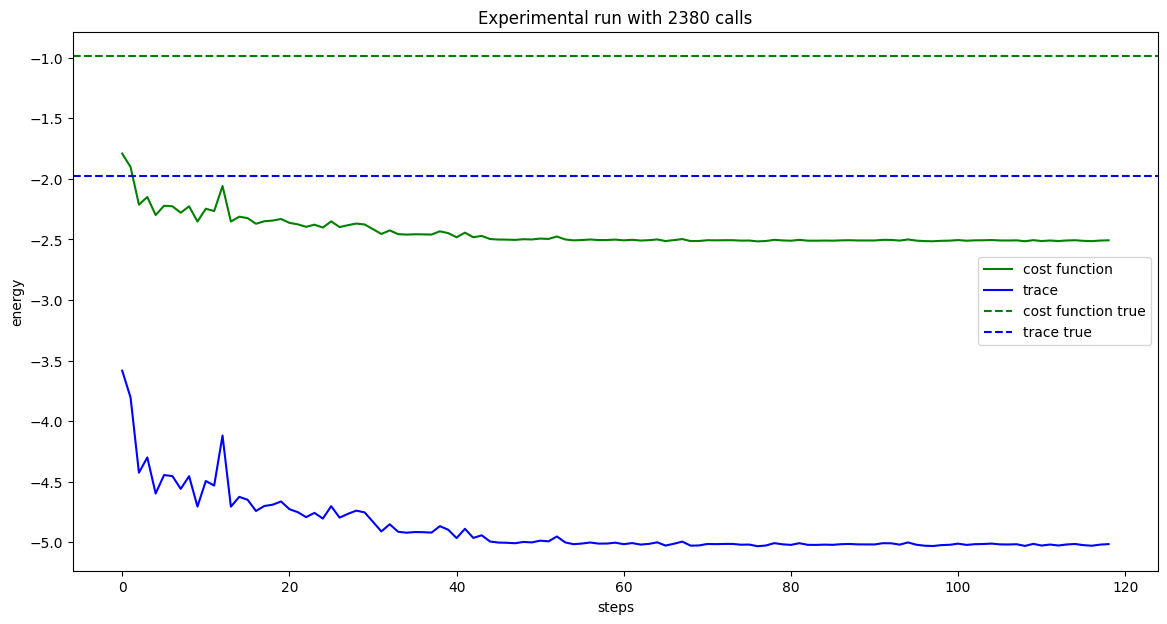

In [18]:
fig, ax = plt.subplots(figsize=(14,7))

trace = np.array(E1_exp)+np.array(E2_exp)

ax.plot(range(len(cost_exp)), cost_exp, color='green', label=f'cost function')
ax.plot(range(len(trace)), trace, color='blue', label=f'trace')
ax.axhline(0.5*energies[0]+0.5*energies[1], ls='--', color='green', label=f'cost function true')
ax.axhline(energies[0]+energies[1], ls='--', color='blue', label=f'trace true')
ax.set_title(f'Experimental run with {calls_exp} calls')
ax.set_ylabel(f'energy')
ax.set_xlabel(f'steps')
ax.legend()
plt.show()

# Debugging

In [49]:
f_i = np.full(66,np.pi)
f_e = np.zeros(66)

theta_meas = [34,35]
phi_meas = [34,35]

meas_circ = {'I': {'phi': [0], 'theta': [np.pi]},
             'X': {'phi': [0], 'theta': [np.pi/2]},
             'Y': {'phi': [np.pi/2], 'theta': [np.pi/2]},
             'Z': {'phi': [0], 'theta': [np.pi]}}

measurement_group = ['ZZ', 'XX', 'XZ', 'ZX', 'YY']

for op in measurement_group:
    f_i = np.full(66,np.pi)
    f_e = np.zeros(66)
    f_i[theta_meas] = meas_circ[op[0]]['theta'] + meas_circ[op[1]]['theta']
    f_e[phi_meas] = meas_circ[op[0]]['phi'] + meas_circ[op[1]]['phi']


    for i,p in enumerate(par_e):
            p.set_value(f_e[i])
    
    for j,q in enumerate(par_i):
        q.set_value(f_i[j])
    print(op)
    print(f_i[theta_meas],f_e[phi_meas])
    pcvl.pdisplay(circuit.compute_unitary())#, output_format='TEXT')

ZZ
[3.14159265 3.14159265] [0. 0.]


<IPython.core.display.Math object>

XX
[1.57079633 1.57079633] [0. 0.]


<IPython.core.display.Math object>

XZ
[1.57079633 3.14159265] [0. 0.]


<IPython.core.display.Math object>

ZX
[3.14159265 1.57079633] [0. 0.]


<IPython.core.display.Math object>

YY
[1.57079633 1.57079633] [1.57079633 1.57079633]


<IPython.core.display.Math object>

In [113]:
theta_par = [12,13,45,46]
theta_cnot_ext = [24,35]
theta_cnot = [28,29,30]
theta_meas = [56,57]
phi_meas = [56,57]
offset_phases = [23,24,29,40,45,46,51,52]
inv_c = 2        


meas_circ = {'I': {'phi': [0], 'theta': [np.pi]},
             'X': {'phi': [0], 'theta': [np.pi/2]},
             'Y': {'phi': [np.pi/2], 'theta': [np.pi/2]},
             'Z': {'phi': [0], 'theta': [np.pi]}}

measurement_group = ['ZZ', 'XX', 'XZ', 'ZX', 'YY']

for op in measurement_group:
    theta = np.full(66,np.pi)
    phi = np.zeros(66)
    theta[theta_meas] = meas_circ[op[0]]['theta'] + meas_circ[op[1]]['theta']
    f_e[phi_meas] = meas_circ[op[0]]['phi'] + meas_circ[op[1]]['phi']
    theta[theta_cnot] = [-np.arccos(1/3),-np.arccos(1/3),np.arccos(1/3)]
    theta[theta_cnot_ext] = [np.pi/2]*2
    # thetas_from_R = 2*np.arcsin(x)
    # theta[theta_par] = x_test
    phi[offset_phases] = np.pi

    for i,p in enumerate(par_e):
        p.set_value(phi[i])
    
    for j,q in enumerate(par_i):
        q.set_value(theta[j])
    print(op)
    print(theta[theta_meas],phi[phi_meas])
    pcvl.pdisplay(circuit.compute_unitary())#, output_format='TEXT')

ZZ
[3.14159265 3.14159265] [0. 0.]


<IPython.core.display.Math object>

XX
[1.57079633 1.57079633] [0. 0.]


<IPython.core.display.Math object>

XZ
[1.57079633 3.14159265] [0. 0.]


<IPython.core.display.Math object>

ZX
[3.14159265 1.57079633] [0. 0.]


<IPython.core.display.Math object>

YY
[1.57079633 1.57079633] [0. 0.]


<IPython.core.display.Math object>

In [51]:
V = 1/np.sqrt(2)*np.array([[1j, 1],[1j,-1]])
X = np.array([[0,1],[1,0]])
Y = np.array([[0,-1j],[1j,0]])
V @ Y @ V.conj().T

array([[ 1.+0.j,  0.+0.j],
       [ 0.+0.j, -1.+0.j]])

In [52]:
print(pcvl.BS.H().compute_unitary())

[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]


In [53]:
P = pcvl.P("phi")
P.set_value(1.0)
ps = pcvl.components.PS(P)
print(ps.compute_unitary())

[[0.54030231+0.84147098j]]


In [54]:
# Build a single isolated MZI
P_phi = pcvl.P("phi")
P_theta = pcvl.P("theta")
mzi = (pcvl.Circuit(2)
       .add(0, pcvl.components.PS(P_phi))
       .add(0, pcvl.BS())
       .add(0, pcvl.components.PS(P_theta))
       .add(0, pcvl.BS()))

# Scan theta with phi=0
for theta in [0, np.pi/4, np.pi/2, np.pi]:
    P_phi.set_value(0)
    P_theta.set_value(theta)
    print(f"theta={theta:.4f}, phi=0")
    print(np.array(mzi.compute_unitary()).round(3))
    print()

theta=0.0000, phi=0
[[0.+0.j 0.+1.j]
 [0.+1.j 0.+0.j]]

theta=0.7854, phi=0
[[-0.146+0.354j -0.354+0.854j]
 [-0.354+0.854j  0.146-0.354j]]

theta=1.5708, phi=0
[[-0.5+0.5j -0.5+0.5j]
 [-0.5+0.5j  0.5-0.5j]]

theta=3.1416, phi=0
[[-1.+0.j -0.+0.j]
 [-0.+0.j  1.-0.j]]



## Debug expectation values

In [50]:
x_test = np.full(4,np.pi)
# x_test = r0[0]
input_state = [[1/np.sqrt(2),1j/np.sqrt(2)],
               [1/np.sqrt(2),1j/np.sqrt(2)]]
measurement_groups = ['II', 'XX', 'YY', 'ZZ', 'YX', 'ZX', 'XY', 'ZY', 'XZ', 'YZ']
all_paulis = ['II', 'IX', 'IY', 'IZ', 'XI', 'XX', 'XY', 'XZ', 'YI', 'YX', 'YY', 'YZ', 'ZI', 'ZX', 'ZY', 'ZZ']


results = P_calc(x_test, measurement_groups, input_state, scheme='qlass')
pauli_groupings = {'II': 'II', 'IX': 'XX', 'IY': 'YY', 'IZ': 'ZZ',
                   'XI': 'XX', 'XX': 'XX', 'XY': 'XY', 'XZ': 'XZ',
                   'YI': 'YY', 'YX': 'YX', 'YY': 'YY', 'YZ': 'YZ',
                   'ZI': 'ZZ', 'ZX': 'ZX', 'ZY': 'ZY', 'ZZ': 'ZZ'}
eig = {'I': np.array([1,  1]),
       'X': np.array([1, -1]),
       'Y': np.array([1, -1]),
       'Z': np.array([1, -1])}
expvalues = {}
for op in all_paulis:
    expvalues[op] = expected_value(results[pauli_groupings[op]], op[0], op[1], eig)
    print(f'<{op}> = ', np.round(expvalues[op],3))
    print(f'counts = ', results[pauli_groupings[op]])
    print(f'probabilities = ', np.round(results[pauli_groupings[op]]/results[pauli_groupings[op]].sum(),2))

<II> =  1.0
counts =  [ 1588561 53963836 54285932 12382523]
probabilities =  [0.01 0.44 0.44 0.1 ]
<IX> =  -0.091
counts =  [27772640 33331579 27781843 33341331]
probabilities =  [0.23 0.27 0.23 0.27]
<IY> =  0.03
counts =  [27783835 27777541 35180972 31488321]
probabilities =  [0.23 0.23 0.29 0.26]
<IZ> =  -0.086
counts =  [ 1588624 53963660 54276313 12380271]
probabilities =  [0.01 0.44 0.44 0.1 ]
<XI> =  -0.0
counts =  [27772640 33331579 27781843 33341331]
probabilities =  [0.23 0.27 0.23 0.27]
<XX> =  0.0
counts =  [27772640 33331579 27781843 33341331]
probabilities =  [0.23 0.27 0.23 0.27]
<XY> =  0.772
counts =  [55043286  6056767  7906133 53211400]
probabilities =  [0.45 0.05 0.06 0.44]
<XZ> =  0.273
counts =  [36264646 24843920 19608805 41508049]
probabilities =  [0.3  0.2  0.16 0.34]
<YI> =  -0.091
counts =  [27783835 27777541 35180972 31488321]
probabilities =  [0.23 0.23 0.29 0.26]
<YX> =  -0.818
counts =  [       0 55561929 55555984 11108411]
probabilities =  [0.   0.45 0.4

In [47]:
# H_1 = {'II': -0.44216633, 'IX':-0.2458943, 'IZ':-0.36997974, 'XI':-0.07340748, 'XX':0.00097788, 'XZ':-1*0.07417185, 'YY': 0.03523796, 'ZI':-0.44476681, 'ZX':-0.04444575, 'ZZ':-0.41780773}
# H_1 = {'II': -0.44216633, 'XI':-0.07340748, 'ZI':-0.44476681} # this works
H_1 = {'YY' : 1.0,'YX' : 1.0,'ZY' : 1.0,}

coeffs = np.array(list(H_1.values()))
print(f'coefficients = ', coeffs)
expval  = np.array([expvalues[op] for op in H_1])
for op in H_1:
    print(f'<{op}> = ', expvalues[op])
H = coeffs @ expval
print(f'E = <H> = ', H)

coefficients =  [1. 1. 1.]
<YY> =  -0.00022431917025544186
<YX> =  -9.099259365288949e-05
<ZY> =  -2.976209627394664e-05
E = <H> =  -0.00034507386018227794


In [48]:
theta_par = [12,13,45,46]
theta_cnot_ext = [24,35]
theta_cnot = [28,29,30]
theta_meas = [56,57]
phi_meas = [56,57]
offset_phases = [23,24,29,40,45,46,51,52]
inv_c = 2        

# chip initialization
theta = np.full(66,np.pi)
phi = np.zeros(66)

# set internal and external phases
theta[theta_cnot] = [-np.arccos(1/3),-np.arccos(1/3),np.arccos(1/3)]
theta[theta_cnot_ext] = [np.pi/2]*2
# thetas_from_R = 2*np.arcsin(x)
theta[theta_par] = x_test
phi[offset_phases] = np.pi
    
if inversion:
    theta[inv_c] = 0

meas_circ = {'I': {'phi': [0], 'theta': [np.pi]},
             'X': {'phi': [0], 'theta': [np.pi/2]},
             'Y': {'phi': [np.pi/2], 'theta': [np.pi/2]},
             'Z': {'phi': [0], 'theta': [np.pi]}}

op = 'II'

theta[theta_meas] = meas_circ[op[0]]['theta'] + meas_circ[op[1]]['theta']
phi[phi_meas] = meas_circ[op[0]]['phi'] + meas_circ[op[1]]['phi']

for i,p in enumerate(par_e):
    p.set_value(phi[i])
    
for j,q in enumerate(par_i):
    q.set_value(theta[j])
    
pcvl.pdisplay(np.abs(circuit.compute_unitary())**2)#, output_format='TEXT')

<IPython.core.display.Math object>